In [ ]:
import json
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import geopandas as gpd
import shapely
import osmnx as ox
from scipy.spatial import cKDTree
from pyproj import Transformer
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

IN_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage3_synced")         # Stage 3 output (1 Hz)
OSM_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/data/reference/osm")                     # saved OpenStreetMap network (downloaded once)
OUT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage4_map_matched")   # 1 Hz + road attributes
REPORT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage4_map_matching")
INVENTORY = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage1_inventory/inventory.csv")   # only used to report results per route
for d in (OSM_DIR, OUT_DIR, REPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)

trip_ids = sorted(p.stem for p in IN_DIR.glob("T*.csv"))
print(f"{len(trip_ids)} synchronised trips from Stage 3   |   osmnx {ox.__version__}")

77 synchronised trips from Stage 3   |   osmnx 2.1.1


In [ ]:
CFG = {
    "crs_metric": "EPSG:32644",     # UTM zone 44N – metres, covers western Sri Lanka
    "area_buffer_m": 300,           # download roads within 300 m of any recorded GPS point
    "candidate_radius_m": 35,       # roads considered for a GPS point (~3x phone GPS error + half road width)
    "max_candidates": 8,            # nearest candidate road segments kept per point (junctions have many)
    "gps_sigma_m": 5,               # phone GPS error (std. dev.) used in the emission probability
    "beta_m": 10,                   # tolerance between road distance and straight-line distance (transition)
    "max_route_m": 400,             # longest road path searched between two consecutive points
    "max_step_s": 5,                # a time gap longer than this restarts the matching chain
    "low_conf_dist_m": 20,          # matched, but GPS more than 20 m from the road -> low confidence
    "ambiguity_m": 3,               # another road of a different class within 3 m of the chosen one -> low confidence
    "signal_radius_m": 30,          # "near a traffic signal"
    "toll_radius_m": 100,           # "near a toll plaza" (plazas are wide)
}
to_metric = Transformer.from_crs("EPSG:4326", CFG["crs_metric"], always_xy=True)
to_wgs = Transformer.from_crs(CFG["crs_metric"], "EPSG:4326", always_xy=True)
pd.Series(CFG, name="value").to_frame()

,value
crs_metric,EPSG:32644
area_buffer_m,300
candidate_radius_m,35
max_candidates,8
gps_sigma_m,5
beta_m,10
max_route_m,400
max_step_s,5
low_conf_dist_m,20
ambiguity_m,3


In [ ]:
pts = []
for tid in trip_ids:
    s = pd.read_csv(IN_DIR / f"{tid}.csv", usecols=["gps_lat", "gps_lon"]).dropna()
    pts.append(s.iloc[::10])                                    # every 10th second is enough to outline the area
pts = pd.concat(pts)
x, y = to_metric.transform(pts["gps_lon"].values, pts["gps_lat"].values)
cells = np.unique(np.round(np.c_[x, y] / 100) * 100, axis=0)          # one point per 100 m cell (fast, low memory)
area_m = shapely.union_all(shapely.buffer(shapely.points(cells), CFG["area_buffer_m"], quad_segs=4)).simplify(50)
area_wgs = shapely.ops.transform(lambda a, b: to_wgs.transform(a, b), area_m)
gpd.GeoSeries([area_wgs], crs="EPSG:4326").to_file(OSM_DIR / "study_area.geojson", driver="GeoJSON")
print(f"Study area: {area_m.area / 1e6:.1f} km2 around {len(pts):,} sampled GPS points ({len(cells):,} 100 m cells)")

/tmp/ipykernel_2524/3332045984.py:9: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  area_wgs = shapely.ops.transform(lambda a, b: to_wgs.transform(a, b), area_m)


Study area: 34.5 km2 around 15,999 sampled GPS points (675 100 m cells)


In [ ]:
GRAPH_FILE = OSM_DIR / "drive_network.graphml"
FEATURE_FILE = OSM_DIR / "signals_and_tolls.geojson"
INFO_FILE = OSM_DIR / "download_info.json"

if GRAPH_FILE.exists():
    G = ox.load_graphml(GRAPH_FILE)
    info = json.loads(INFO_FILE.read_text())
    print(f"Loaded saved OSM network (downloaded {info['downloaded']})")
else:
    print("Downloading OSM drivable road network (needs internet, ~1-3 min)...")
    G = ox.graph_from_polygon(area_wgs, network_type="drive", simplify=False, retain_all=False, truncate_by_edge=True)
    # simplify, but never merge road pieces whose class or name differs (keeps e.g. motorway vs ramp apart)
    G = ox.simplify_graph(G, edge_attrs_differ=["highway", "name"])
    nx.set_node_attributes(G, ox.stats.count_streets_per_node(G), "street_count")   # roads meeting at each node
    ox.save_graphml(G, GRAPH_FILE)
    try:
        feats = ox.features_from_polygon(area_wgs, tags={"highway": ["traffic_signals"], "barrier": ["toll_booth"]})
        feats = feats.reset_index()[[c for c in ("highway", "barrier", "geometry") if c in feats.reset_index().columns]]
        feats["geometry"] = feats.geometry.centroid                 # plazas mapped as areas -> centre point
    except Exception as e:                                          # no such features in the area
        print("No signal / toll features found:", e)
        feats = gpd.GeoDataFrame({"highway": [], "barrier": []}, geometry=[], crs="EPSG:4326")
    feats.to_file(FEATURE_FILE, driver="GeoJSON")
    info = {"downloaded": dt.datetime.now().isoformat(timespec="seconds"), "osmnx": ox.__version__,
            "source": "OpenStreetMap contributors (ODbL) via Overpass API", "network_type": "drive"}
    INFO_FILE.write_text(json.dumps(info, indent=2))
    print("Saved to", OSM_DIR)

features = gpd.read_file(FEATURE_FILE)
print(f"Network: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} directed road segments; "
      f"{len(features)} signal / toll features")

Saved to /content/drive/MyDrive/Colab Notebooks/Component01/data/reference/osm
Network: 765 nodes, 1,579 directed road segments; 62 signal / toll features


/tmp/ipykernel_2524/4236861702.py:19: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  feats["geometry"] = feats.geometry.centroid                 # plazas mapped as areas -> centre point


In [ ]:
def first(v):
    """OSM tags can be lists after simplification (e.g. ['primary', 'secondary']); keep the first value."""
    if isinstance(v, list):
        return v[0] if v else np.nan
    if isinstance(v, str) and v.startswith("[") and v.endswith("]"):      # list stored as text in GraphML
        items = [s.strip(" '\"") for s in v[1:-1].split(",")]
        return items[0] if items else np.nan
    return v

def to_number(v):
    v = first(v)
    try:
        return float(str(v).split()[0].split(";")[0])
    except (ValueError, TypeError):
        return np.nan

Gp = ox.project_graph(G, to_crs=CFG["crs_metric"])
nodes, edges = ox.graph_to_gdfs(Gp)
edges = edges.reset_index()                                             # columns u, v, key
edges["road_class"] = edges["highway"].map(first)
edges["road_name"] = edges["name"].map(first) if "name" in edges else np.nan
edges["osm_way_id"] = edges["osmid"].map(first)
edges["maxspeed_kmh"] = edges["maxspeed"].map(to_number) if "maxspeed" in edges else np.nan
edges["lanes"] = edges["lanes"].map(to_number) if "lanes" in edges else np.nan
edges["oneway"] = edges["oneway"].astype(str).str.lower().isin(["true", "yes", "1"]) if "oneway" in edges else False

geoms = edges.geometry.values
# lengths measured on the projected geometry, so they match positions measured along the same geometry
edge_len = shapely.length(geoms)
edge_u, edge_v = edges["u"].values, edges["v"].values
nx.set_edge_attributes(Gp, dict(zip(zip(edge_u, edge_v, edges["key"].values), edge_len)), "len_m")
tree = shapely.STRtree(geoms)
# a two-way street is two directed edges (u->v and v->u); remember each edge's "twin" in the other direction
_index = {(u, v, w): i for i, (u, v, w) in enumerate(zip(edge_u, edge_v, edges["osm_way_id"]))}
twin = {i: _index.get((v, u, w)) for (u, v, w), i in _index.items()}

junction_xy = nodes.loc[nodes["street_count"] >= 3, "geometry"].get_coordinates().values
junction_tree = cKDTree(junction_xy)

feat_m = features.to_crs(CFG["crs_metric"])
def feature_tree(mask):
    xy = feat_m.loc[mask].geometry.get_coordinates().values
    return cKDTree(xy) if len(xy) else None
signal_tree = feature_tree(feat_m.get("highway", pd.Series(dtype=str)).astype(str).eq("traffic_signals"))
toll_tree = feature_tree(feat_m.get("barrier", pd.Series(dtype=str)).astype(str).eq("toll_booth"))

summary_net = (edges.groupby("road_class")["length"].sum() / 1000 / 2).round(1)     # /2: two directions
print(f"Junctions: {len(junction_xy):,}   signals: {0 if signal_tree is None else signal_tree.n}   "
      f"toll booths: {0 if toll_tree is None else toll_tree.n}")
summary_net.sort_values(ascending=False).to_frame("approx. road length (km)")

Junctions: 458   signals: 40   toll booths: 22


,approx. road length (km)
road_class,
residential,57.4
motorway,34.5
primary,8.8
tertiary,7.5
motorway_link,7.4
living_street,6.2
trunk,2.9
unclassified,2.8
trunk_link,0.2


In [8]:
_sp_cache = {}
def path_lengths_from(node):
    """Road distances (m) from a node to every node within max_route_m (cached)."""
    if node not in _sp_cache:
        _sp_cache[node] = nx.single_source_dijkstra_path_length(Gp, node, cutoff=CFG["max_route_m"], weight="len_m")
    return _sp_cache[node]


def road_distance(e1, p1, e2, p2):
    """Driving distance from position p1 on directed edge e1 to position p2 on edge e2 (inf if impossible)."""
    if e1 == e2:
        d = p2 - p1
        return max(d, 0.0) if d > -CFG["gps_sigma_m"] else np.inf    # small backwards = GPS noise
    if twin.get(e1) == e2:                                            # same street, other direction
        return abs((edge_len[e1] - p2) - p1)                         # (GPS noise while stopped / turning)
    to_end = edge_len[e1] - p1
    via = path_lengths_from(edge_v[e1]).get(edge_u[e2])
    return np.inf if via is None else to_end + via + p2


def candidates(x, y):
    """For each point: up to max_candidates nearby directed edges, with distance and position along the edge."""
    pts = shapely.points(x, y)
    pi, ei = tree.query(pts, predicate="dwithin", distance=CFG["candidate_radius_m"])
    dist = shapely.distance(pts[pi], geoms[ei])
    pos = shapely.line_locate_point(geoms[ei], pts[pi])
    c = pd.DataFrame({"pt": pi, "edge": ei, "dist": dist, "pos": pos}).sort_values(["pt", "dist"])
    c = c.groupby("pt").head(CFG["max_candidates"])
    return {p: g[["edge", "dist", "pos"]].values for p, g in c.groupby("pt")}


def viterbi(cands, xs, ys):
    """Most likely sequence of candidates for one continuous chain of points (Newson & Krumm 2009 HMM)."""
    n = len(cands)
    emis = [-0.5 * (c[:, 1] / CFG["gps_sigma_m"]) ** 2 for c in cands]
    score, back = [emis[0]], [None]
    for t in range(1, n):
        prev, cur = cands[t - 1], cands[t]
        straight = np.hypot(xs[t] - xs[t - 1], ys[t] - ys[t - 1])
        trans = np.full((len(prev), len(cur)), -np.inf)
        for i, (e1, _, p1) in enumerate(prev):
            for j, (e2, _, p2) in enumerate(cur):
                rd = road_distance(int(e1), p1, int(e2), p2)
                if np.isfinite(rd):
                    trans[i, j] = -abs(rd - straight) / CFG["beta_m"]
        total = score[-1][:, None] + trans
        if not np.isfinite(total).any():                  # no connected path -> caller restarts the chain
            return None, t
        back.append(total.argmax(axis=0))
        score.append(total.max(axis=0) + emis[t])
    path = [int(np.argmax(score[-1]))]
    for t in range(n - 1, 0, -1):
        path.append(int(back[t][path[-1]]))
    return path[::-1], n

In [9]:
def match_trip(tid):
    s = pd.read_csv(IN_DIR / f"{tid}.csv", parse_dates=["timestamp"])
    has_gps = s["gps_lat"].notna().values
    x = np.full(len(s), np.nan); y = np.full(len(s), np.nan)
    x[has_gps], y[has_gps] = to_metric.transform(s.loc[has_gps, "gps_lon"].values, s.loc[has_gps, "gps_lat"].values)

    idx_gps = np.where(has_gps)[0]
    cand = candidates(x[idx_gps], y[idx_gps])
    chosen = {}                                            # row index -> (edge, dist, pos, n_candidates)
    # build chains: consecutive rows with GPS, candidates, same segment and time step <= max_step_s
    chain = []
    def flush(chain):
        k = 0
        while k < len(chain):
            rows = chain[k:]
            cs = [cand[r[1]] for r in rows]
            path, stop = viterbi(cs, x[[r[0] for r in rows]], y[[r[0] for r in rows]])
            if path is None:                               # break: match the part before 'stop', restart there
                sub = rows[:stop]
                path, _ = viterbi([cand[r[1]] for r in sub], x[[r[0] for r in sub]], y[[r[0] for r in sub]])
                rows = sub
            for (row, ci), j in zip(rows, path):
                e, d, p = cand[ci][j]
                chosen[row] = (int(e), d, p, len(cand[ci]))
            k += len(rows)
            n_breaks[0] += int(k < len(chain))
    n_breaks = [0]
    t_s, seg = s["t_s"].values, s["segment_id"].values
    for k, row in enumerate(idx_gps):
        if k not in cand:                                  # no road within candidate radius
            flush(chain); chain = []
            continue
        if chain and (t_s[row] - t_s[chain[-1][0]] > CFG["max_step_s"] or seg[row] != seg[chain[-1][0]]):
            flush(chain); chain = []
        chain.append((row, k))
    flush(chain)

    # --- attach road attributes
    out = s.copy()
    e_idx = np.full(len(s), -1)
    out["match_dist_m"] = np.nan
    out["n_candidates"] = 0
    pos = np.full(len(s), np.nan)
    for row, (e, d, p, nc) in chosen.items():
        e_idx[row], pos[row] = e, p
        out.at[row, "match_dist_m"] = round(d, 2)
        out.at[row, "n_candidates"] = nc
    m = e_idx >= 0
    for col in ("osm_way_id", "road_name", "road_class", "maxspeed_kmh", "lanes", "oneway"):
        vals = np.full(len(s), None, dtype=object)              # empty where no road was matched
        vals[m] = edges[col].values[e_idx[m]]
        out[col] = vals
    out["is_ramp"] = out["road_class"].astype(str).str.endswith("_link")

    snapped = shapely.line_interpolate_point(geoms[e_idx[m]], pos[m])
    sx, sy = shapely.get_x(snapped), shapely.get_y(snapped)
    lon, lat = to_wgs.transform(sx, sy)
    out["snapped_lat"], out["snapped_lon"] = np.nan, np.nan
    out.loc[m, "snapped_lat"], out.loc[m, "snapped_lon"] = lat, lon
    out["dist_to_junction_m"] = np.nan
    out.loc[m, "dist_to_junction_m"] = np.round(junction_tree.query(np.c_[sx, sy])[0], 1)
    out["near_signal"] = False
    out["near_toll"] = False
    if signal_tree is not None:
        out.loc[m, "near_signal"] = signal_tree.query(np.c_[sx, sy])[0] <= CFG["signal_radius_m"]
    if toll_tree is not None:
        out.loc[m, "near_toll"] = toll_tree.query(np.c_[sx, sy])[0] <= CFG["toll_radius_m"]

    # --- ambiguity: another candidate of a DIFFERENT road class almost as close
    amb = np.zeros(len(s), bool)
    for k, row in enumerate(idx_gps):
        if row in chosen and k in cand:
            c = cand[k]; e, d = chosen[row][0], chosen[row][1]
            other = [cd for ce, cd, _ in c if edges["road_class"].values[int(ce)] != edges["road_class"].values[e]]
            amb[row] = bool(other) and min(other) - d < CFG["ambiguity_m"]

    flag = np.full(len(s), "no_gps", dtype=object)
    flag[has_gps] = "unmatched"
    flag[m] = "matched"
    low = m & ((out["match_dist_m"].values > CFG["low_conf_dist_m"]) | amb)
    flag[low] = "low_confidence"
    out["match_flag"] = flag

    # --- jumps between consecutive matched seconds (road distance much longer than straight line)
    jumps = 0
    rows_m = np.where(m)[0]
    for a, b in zip(rows_m[:-1], rows_m[1:]):
        if b - a == 1 and seg[a] == seg[b]:
            rd = road_distance(e_idx[a], pos[a], e_idx[b], pos[b])
            if not np.isfinite(rd) or rd - np.hypot(x[b] - x[a], y[b] - y[a]) > 50:
                jumps += 1
    vc = pd.Series(flag).value_counts(normalize=True) * 100
    diag = {"trip_id": tid, "seconds": len(s),
            **{f"{k}_%": round(vc.get(k, 0), 1) for k in ("matched", "low_confidence", "unmatched", "no_gps")},
            "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
            "p95_dist_m": round(np.nanpercentile(out["match_dist_m"], 95), 2) if m.any() else np.nan,
            "chain_breaks": n_breaks[0], "path_jumps": jumps,
            "fast_on_minor_road_s": int(((out["speed_kmh"] > 100) &
                                         out["road_class"].isin(["residential", "unclassified", "living_street"])).sum())}
    return out, diag

In [10]:
import time
all_diag = []
t_start = time.time()
for i, tid in enumerate(trip_ids, 1):
    out, diag = match_trip(tid)
    out.to_csv(OUT_DIR / f"{tid}.csv", index=False)
    all_diag.append(diag)
    if i % 10 == 0 or i == len(trip_ids):
        print(f"{i}/{len(trip_ids)} trips matched  ({time.time() - t_start:.0f} s)")

diagnostics = pd.DataFrame(all_diag)
diagnostics.to_csv(REPORT_DIR / "matching_diagnostics.csv", index=False)
diagnostics.head(10)

/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  s = pd.read_csv(IN_DIR / f"{tid}.csv", parse_dates=["timestamp"])
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m

10/77 trips matched  (8 s)


/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"

20/77 trips matched  (13 s)


/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),


...

/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),
/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),


70/77 trips matched  (52 s)


/tmp/ipykernel_2524/1067727703.py:95: RuntimeWarning: All-NaN slice encountered
  "median_dist_m": round(np.nanmedian(out["match_dist_m"]), 2),


77/77 trips matched  (61 s)


,trip_id,seconds,matched_%,low_confidence_%,unmatched_%,no_gps_%,median_dist_m,p95_dist_m,chain_breaks,path_jumps,fast_on_minor_road_s
0,T001,1767,80.0,20.0,0.0,0.0,11.65,23.47,27,29,0
1,T002,1627,95.8,4.1,0.0,0.1,1.42,4.28,0,0,0
2,T003,1991,0.0,0.0,99.9,0.1,NaN,NaN,0,0,0
3,T004,2303,0.0,0.0,100.0,0.0,NaN,NaN,0,0,0
4,T005,1784,78.4,21.6,0.0,0.0,11.92,23.62,29,31,0
5,T006,3142,0.0,0.0,99.8,0.2,NaN,NaN,0,0,0
6,T007,1675,93.6,3.7,0.0,2.7,1.55,4.60,0,0,0
7,T008,1266,96.9,3.1,0.0,0.0,1.51,4.38,0,0,0
8,T009,5424,0.0,0.0,100.0,0.0,NaN,NaN,0,0,0
9,T010,3312,0.0,0.0,99.8,0.2,NaN,NaN,0,0,0


In [11]:
w = diagnostics["seconds"]
overall = pd.Series({k: round((diagnostics[f"{k}_%"] * w).sum() / w.sum(), 1)
                     for k in ("matched", "low_confidence", "unmatched", "no_gps")}, name="% of seconds")
display(overall.to_frame())
print(f"GPS-to-road distance: median {diagnostics['median_dist_m'].median():.1f} m, "
      f"95th percentile {diagnostics['p95_dist_m'].median():.1f} m (median over trips)")

route = (pd.read_csv(INVENTORY).set_index("trip_id")["route_hint"] if INVENTORY.exists()
         else pd.Series(dtype=str))
rows = []
for tid in trip_ids:
    o = pd.read_csv(OUT_DIR / f"{tid}.csv", usecols=["road_class", "match_flag"])
    o = o[o["match_flag"].isin(["matched", "low_confidence"])]
    rows.append(o["road_class"].value_counts().rename(route.get(tid, "all trips")))
share = (pd.concat(rows, axis=1).T.groupby(level=0).sum().T.fillna(0))
share = (share / share.sum() * 100).round(1)
share = share[share.max(axis=1) >= 0.5].sort_values(share.columns[0], ascending=False)
share.to_csv(REPORT_DIR / "road_class_share.csv")
print("Share of matched driving time by road class (%):")
share

,% of seconds
matched,36.2
low_confidence,3.0
unmatched,58.4
no_gps,2.3


GPS-to-road distance: median 1.7 m, 95th percentile 4.9 m (median over trips)
Share of matched driving time by road class (%):


,all trips
road_class,
motorway,79.1
motorway_link,13.4
trunk,4.5
primary,2.4


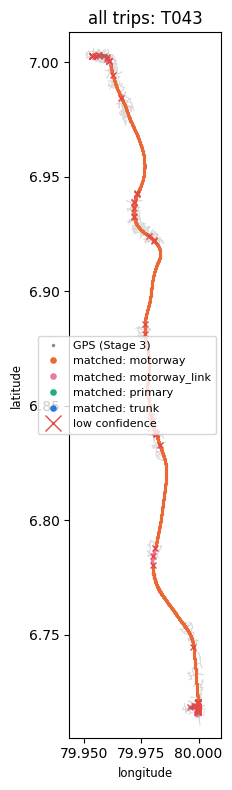

In [19]:
example = []
for r in (route.unique() if len(route) else ["all trips"]):
    cand_trips = diagnostics[diagnostics["trip_id"].map(lambda t: route.get(t, "all trips")) == r]
    good = cand_trips[cand_trips["matched_%"] >= 95]
    if len(good):                                          # longest well-matched trip of this route as the example
        example.append((r, good.sort_values("seconds", ascending=False).iloc[0]["trip_id"]))

palette = {"motorway": "#eb6834", "motorway_link": "#e87ba4", "trunk": "#2a78d6", "primary": "#1baf7a",
           "secondary": "#eda100", "tertiary": "#6250d6"}
fig, axes = plt.subplots(1, len(example), figsize=(7 * len(example), 8))
axes = np.atleast_1d(axes)
edges_wgs = edges.to_crs("EPSG:4326")
for ax, (r, tid) in zip(axes, example):
    o = pd.read_csv(OUT_DIR / f"{tid}.csv")
    pad = 0.01
    box = (o["gps_lon"].min() - pad, o["gps_lon"].max() + pad, o["gps_lat"].min() - pad, o["gps_lat"].max() + pad)
    edges_wgs.cx[box[0]:box[1], box[2]:box[3]].plot(ax=ax, color="0.85", lw=0.6)
    ax.plot(o["gps_lon"], o["gps_lat"], ".", ms=1, color="0.55", label="GPS (Stage 3)")
    mm = o[o["match_flag"] == "matched"]
    for cls, g in mm.groupby("road_class"):
        ax.plot(g["snapped_lon"], g["snapped_lat"], ".", ms=2.5, color=palette.get(cls, "#52514e"), label=f"matched: {cls}")
    lc = o[o["match_flag"] == "low_confidence"]
    ax.plot(lc["snapped_lon"], lc["snapped_lat"], "x", ms=4, color="#e34948", label="low confidence")
    ax.set(xlim=box[:2], ylim=box[2:], title=f"{r}: {tid}", xlabel="longitude", ylabel="latitude")
    ax.set_aspect("equal"); ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    ax.legend(loc="best", fontsize=8, markerscale=3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "map_matching_examples.png", dpi=150)
plt.show()

In [13]:
checks = {}
for tid in trip_ids:
    o = pd.read_csv(OUT_DIR / f"{tid}.csv")
    s3 = pd.read_csv(IN_DIR / f"{tid}.csv", usecols=["timestamp", "speed_kmh"])
    checks.setdefault("same rows and timestamps as Stage 3", []).append(
        len(o) == len(s3) and (o["timestamp"].values == s3["timestamp"].values).all())
    checks.setdefault("no road assigned without GPS", []).append(
        bool(o.loc[o["gps_lat"].isna(), "road_class"].isna().all()))
    matched = o["match_flag"].isin(["matched", "low_confidence"])
    checks.setdefault("matched points within candidate radius", []).append(
        bool((o.loc[matched, "match_dist_m"] <= CFG["candidate_radius_m"]).all()))
d = diagnostics
checks["at least 95 % of GPS seconds matched"] = list(
    ((d["matched_%"] + d["low_confidence_%"]) >= 0.95 * (100 - d["no_gps_%"])).values)
checks["no impossible jumps between roads"] = list((d["path_jumps"] == 0).values)
checks["no >100 km/h on residential roads"] = list((d["fast_on_minor_road_s"] == 0).values)

verification = pd.DataFrame({k: [f"{sum(v)}/{len(v)}", "PASS" if all(v) else "CHECK"] for k, v in checks.items()},
                            index=["trips passing", "result"]).T
verification

,trips passing,result
same rows and timestamps as Stage 3,77/77,PASS
no road assigned without GPS,77/77,PASS
matched points within candidate radius,77/77,PASS
at least 95 % of GPS seconds matched,39/77,CHECK
no impossible jumps between roads,67/77,CHECK
no >100 km/h on residential roads,77/77,PASS


In [14]:
print("STAGE 4 – GPS MAP MATCHING: KEY RESULTS")
print("-" * 60)
print(f"OSM network: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} road segments (downloaded {info['downloaded']})")
print(f"Trips matched: {len(diagnostics)}  |  seconds: {diagnostics['seconds'].sum():,}")
for k, v in overall.items():
    print(f"  {k:15s}: {v}% of seconds")
print(f"GPS-to-road distance: median {diagnostics['median_dist_m'].median():.1f} m, "
      f"95th percentile {diagnostics['p95_dist_m'].median():.1f} m")
print(f"Chain restarts: {diagnostics['chain_breaks'].sum()}  |  impossible jumps: {diagnostics['path_jumps'].sum()}")
for col in share.columns:
    top = share[col].sort_values(ascending=False).head(3)
    print(f"  {col}: " + ", ".join(f"{k} {v}%" for k, v in top.items()))
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 4 – GPS MAP MATCHING: KEY RESULTS
------------------------------------------------------------
OSM network: 765 nodes, 1,579 road segments (downloaded 2026-10-21T05:04:59)
Trips matched: 77  |  seconds: 163,461
  matched        : 36.2% of seconds
  low_confidence : 3.0% of seconds
  unmatched      : 58.4% of seconds
  no_gps         : 2.3% of seconds
GPS-to-road distance: median 1.7 m, 95th percentile 4.9 m
Chain restarts: 215  |  impossible jumps: 236
  all trips: motorway 79.1%, motorway_link 13.4%, trunk 4.5%
Verification: see table above


In [15]:
pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage4_map_matching/matching_diagnostics.csv")

,trip_id,seconds,matched_%,low_confidence_%,unmatched_%,no_gps_%,median_dist_m,p95_dist_m,chain_breaks,path_jumps,fast_on_minor_road_s
0,T001,1767,80.0,20.0,0.0,0.0,11.65,23.47,27,29,0
1,T002,1627,95.8,4.1,0.0,0.1,1.42,4.28,0,0,0
2,T003,1991,0.0,0.0,99.9,0.1,NaN,NaN,0,0,0
3,T004,2303,0.0,0.0,100.0,0.0,NaN,NaN,0,0,0
4,T005,1784,78.4,21.6,0.0,0.0,11.92,23.62,29,31,0
...,...,...,...,...,...,...,...,...,...,...,...
72,T073,1053,82.2,17.8,0.0,0.0,11.74,22.73,12,13,0
73,T074,1788,72.4,4.3,0.0,23.3,1.75,4.94,0,0,0
74,T075,1841,83.3,2.8,0.0,14.0,1.70,5.00,0,0,0
75,T076,1744,77.9,22.1,0.0,0.0,12.38,23.92,27,30,0


In [16]:
pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage4_map_matching/road_class_share.csv")

,road_class,all trips
0,motorway,79.1
1,motorway_link,13.4
2,trunk,4.5
3,primary,2.4
